# Stage 1 (YOLO pre-filter): progress update

My part of the project is Stage 1: the cheap YOLO part that runs on every frame and decides which moments are worth sending to the VLM.
The VLM is slow, so the less video it has to look at the better. But if Stage 1 misses an event, the VLM never sees it,
so **missing events is the thing I care about most**, and too many false alarms comes second.

This notebook covers what Stage 1 does now, how I test it, the results, and what I tried this week to push recall up (including what didn't work).
Everything runs from cached YOLO outputs, so the notebook runs in under a minute.

**Demo videos** (open these to see it running): `demo/loitering_demo.mp4` and `demo/littering_demo.mp4`.

## 1. What Stage 1 does

```
video ──► YOLO26s (people + bags/bottles) + ByteTrack tracking + YOLO26s-pose (body keypoints)      ~100-125 ms per frame on my laptop CPU
      ──► simple rules  ──►  "candidates": time window + crop of the person + a hint for the VLM  ──►  VLM (Stage 2)
```

The rules I have right now:

| Rule | What it looks for | Meant for |
|---|---|---|
| `reach_down` | a wrist goes down to about knee height (person bending to the ground). Ignores people cut off by the frame edge and unsure keypoints | littering |
| `sustained_presence` | a person stays in roughly the same spot for 20 s (re-sent every 30 s if they keep staying) | loitering, smoking, rough sleeping |
| `long_presence` (new) | the same person stays **in view** for a long time, even if they walk around, as long as they stay within ~4 body-heights of one area (re-sent every 60 s) | loitering, pacing, wandering |
| `fast_motion` | a person moves faster than 1.2 body-heights per second | running, chasing |
| `unattended_object` | a bag whose owner has walked away, or with nobody around, for more than 10 s. A bag someone is carrying or wearing never counts | unattended items |
| `object_appeared` (new) | a bag that suddenly appears on its own, away from people, and stays put (e.g. it was thrown or dropped) | thrown / dropped items, littering |

All distances are in body-heights rather than pixels, so the same setting works whether people are near or far.
If several rules fire on the same person within 2.5 s, only one candidate is sent, so the VLM doesn't get the same person twice.

So loitering has two time limits: a short one for standing still (20 s) and a longer one for just being around (`long_presence`).
The longer one has to be longer than people normally take to walk through the scene, and that depends on the camera,
so I set it from a few minutes of that camera's normal footage (right now that's only done for the loitering camera).

## 2. How I test it

Datasets:
* **Littering**: 330 short clips (30 frames each) of 5 actions: dropping, dumping, putting-down, throwing, tossing. The person littering is boxed in every frame.
  I had to rebuild this dataset first (see section 7).
* **Loitering**: the videos in our `data/loitering` folder (these come from the CUHK Avenue dataset). The labelled events are things like
  running, throwing stuff and odd behaviour in front of the camera. The training videos have no events at all, so I use them as **normal footage** to count false alarms.
* **Smoking**: factory CCTV at about 1 frame per second, with smokers boxed.

What I measure:
* **Event recall**: out of all the labelled events, how many got at least one candidate at the right time. *This is the main number.*
* **Crop recall**: same, but the crop sent to the VLM must also contain the right person (not someone standing next to them).
* **Video skipped**: how much of the video the VLM doesn't have to look at.
* **False alarms per minute**: candidates on normal footage where nothing happens.

To keep myself honest I split every dataset in half. I tuned all thresholds on one half and only ran the final numbers on the other half once.
I also compare against a **random guess**: pick a random person at the same moments my rule fires. If my rule isn't better than that, it's not really detecting anything.

In [1]:
import pickle
from dataclasses import replace
from functools import partial
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "exp")
from exp_harness import load_splits
from stage1_gate import DEFAULT_RULES, GateConfig, calibrate_inview
sys.path.insert(0, "tools")
from compare_models import model_splits
from stage1_report import (draw_case, false_alarm_rate, find_relinks, headline_table, id_fragmentation,
                           pick_example, recall_by_tag, relink_panel, show_grid)
from random_control import lift

pd.set_option("display.precision", 1)
MODEL = "s"                                                         # YOLO26 size used for this report
TUNE, TEST = model_splits(MODEL, heldout=False), model_splits(MODEL, heldout=True)   # tune half / held-out half

# in-view threshold for the loitering camera, set from the TUNE half of its normal footage only
LOITER_CAM = GateConfig(inview_s=calibrate_inview([r for _, r in TUNE["normal"]]))
CFG = GateConfig()                                       # other cameras: in-view at the default 120 s
print(f"model YOLO26s; loitering camera in-view threshold {LOITER_CAM.inview_s:.0f} s")
print({k: len(v) for k, v in TEST.items()}, "held-out sequences")

model YOLO26s; loitering camera in-view threshold 60 s
{'avenue': 10, 'normal': 8, 'smoking': 232, 'littering': 100} held-out sequences


## 3. Results (held-out half)

In [2]:
table, details = headline_table([
    ("Littering", TEST["littering"], DEFAULT_RULES),
    ("Loitering", TEST["avenue"], DEFAULT_RULES, LOITER_CAM),
    ("Smoking", TEST["smoking"], DEFAULT_RULES),
], CFG)
table.T

run,Littering,Loitering,Smoking
labelled events,100.0,20.0,364.0
Event recall %,72.0,80.0,36.0
Crop recall %,56.0,60.0,12.4
Candidates,131.0,35.0,279.0
Candidate precision %,42.7,40.0,17.9
Candidates / min,26.2,7.1,4.4
Review reduction %,29.7,58.9,63.4
Person-baseline reduction %,0.0,0.0,0.2
Anomalous frames %,99.9,21.7,47.9


How to read this:
* **Littering.** 72% of clips get a candidate, and 56% have the right person in the crop. Every frame of a littering clip is labelled as the event, so "video skipped" doesn't really mean anything here.
* **Loitering.** 16 of the 20 events (80%) get a candidate, and 60% have the right person, while the VLM gets to skip 59% of these videos. Most of the misses are "someone walks close past the camera" events. Nothing in my rules looks for that since I removed `near_camera` (section 4).
* **Smoking.** 36% of smoking events get a candidate, but only 12% with the right person. That's better than with the nano model (28%), because the bigger model finds the small, far-away workers better, but it's still low. This dataset is about 1 frame per second with gaps, so the "stays in one spot" rules hardly ever get enough continuous footage. I think it's mostly a data problem, but I can't prove that until we have continuous smoking video.
* **Sending every frame that has a person in it** would skip almost none of the video, so the filtering is coming from the rules.

### Is it better than guessing?

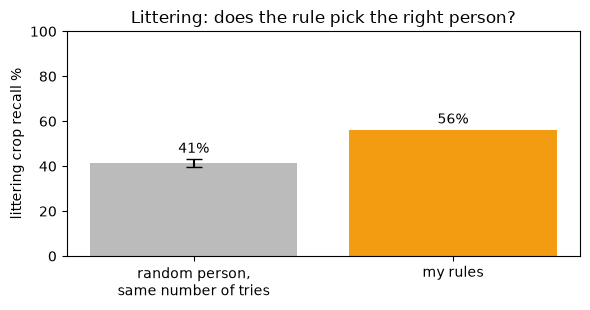

In [3]:
m, c, s = lift(partial(__import__("exp_harness").baseline, cfg=CFG), TEST["littering"])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["random person,\nsame number of tries", "my rules"], [c, m], color=["#bbbbbb", "#f39c12"])
ax.errorbar([0], [c], yerr=[s], color="black", capsize=6)
for x, v, top in [(0, c, c + s), (1, m, m)]:
    ax.text(x, top + 3, f"{v:.0f}%", ha="center")
ax.set_ylabel("littering crop recall %"); ax.set_ylim(0, 100); ax.set_title("Littering: does the rule pick the right person?")
plt.tight_layout(); plt.show()

The grey bar is what you'd get by picking a random person at the same moments my rules fire: about 41%. My rules get 56%, so they pick the right person clearly more often than chance (about 15 points better).

### Littering by action

In [4]:
recall_by_tag(details["Littering"])

,clips,event recall %,crop recall %
action,,,
dropping,20,45.0,35.0
dumping,20,100.0,95.0
putting-down,20,90.0,85.0
throwing,20,65.0,30.0
tossing,20,60.0,35.0


The actions where the person bends down are caught well: dumping 95% and putting-down 85% crop recall, because `reach_down` is basically a bending detector. Throwing (30%), tossing (35%) and dropping (35%) are weak because the person doesn't bend down; the item just leaves their hand. The new `object_appeared` cue only helps with bags (backpack, handbag, suitcase, bottle, cup), and most littered items aren't any of those.

### False alarms on normal footage

In [5]:
false_alarm_rate(TEST["normal"], LOITER_CAM)

,candidates,per minute
event type,,
fast_motion,7,1.4
long_presence,1,0.2
object_appeared,3,0.6
reach_down,3,0.6
sustained_presence,16,3.1
all,30,5.9


On about 5 minutes of normal footage, Stage 1 sends about **6 false candidates per minute**. Half of them are `sustained_presence` (people waiting around for 20 s, which the VLM should dismiss quickly). The fixes this round brought `reach_down` false alarms down to 0.6 per minute, and the new `object_appeared` cue adds about 0.6 per minute.

### Examples
Green box = labelled person/event, red box = what Stage 1 sent to the VLM. One hit and one miss per dataset.

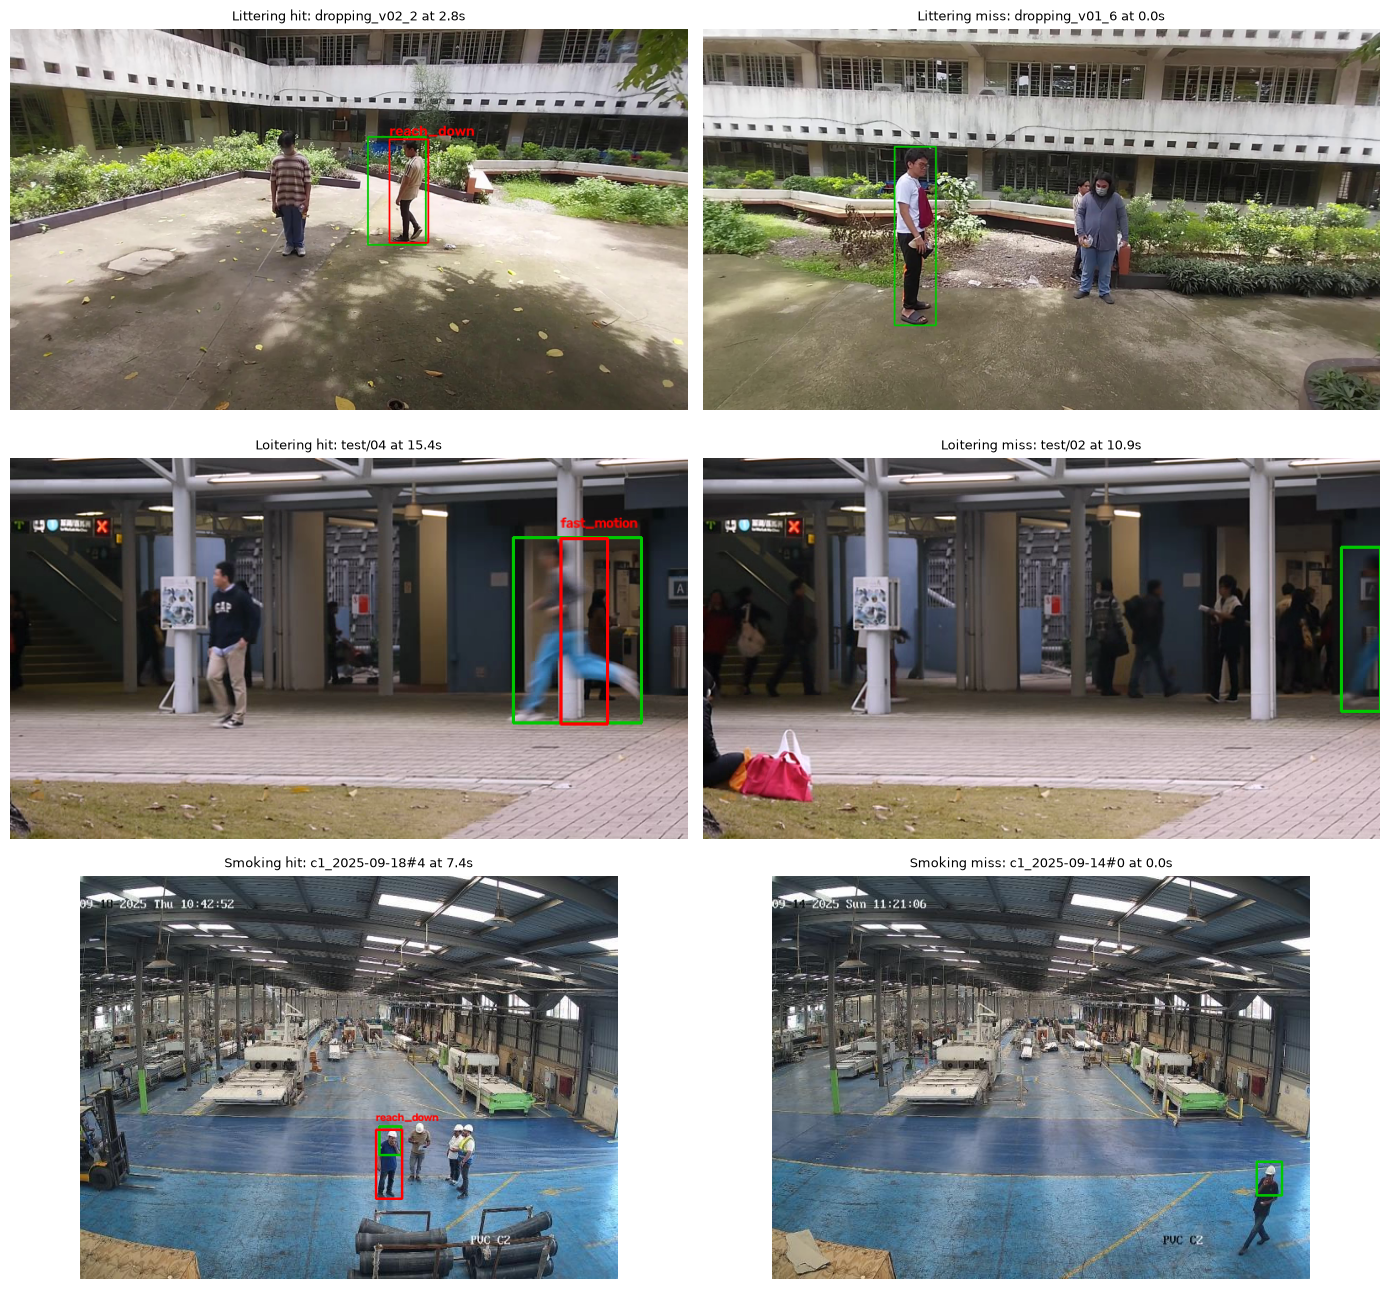

In [6]:
cases = []
for name, res, cfg in [("Littering", TEST["littering"], CFG), ("Loitering", TEST["avenue"], LOITER_CAM),
                       ("Smoking", TEST["smoking"], CFG)]:
    for kind in ("hit", "miss"):
        found = pick_example(res, cfg, kind)
        if found:
            g, r, t = found
            cases.append(draw_case(g, r, cfg, t, f"{name} {kind}: {g.seq.seq_id} at {t:.1f}s"))
show_grid(cases, cols=2, width=14)

## 4. Trying to push recall up

This week I tried five different ideas to catch more events, and tuned each of them on the tune half only:
1. **Littering pose cues**: arm stretched out, hand below the hip (aimed at throwing, tossing and dropping).
2. **"Unusual pose" model**: learn what normal people's poses look like from normal footage and flag anything unusual.
3. **Motion anomalies**: running, walking the wrong way, thrown objects, people in unusual places.
4. **Smoking dwell, done differently**: measure how long someone stays at a *spot* rather than per track ID, because track IDs break a lot at 1 fps.
5. **Crop policy**: when a rule fires, also send a crop of another person nearby, in case the rule picked the wrong person.

On the tune half several of these looked amazing (littering crop recall 52% → 80%, loitering 100%, smoking 43% → 64%). Before believing that, I checked each one two ways: the random-person test, and looking for anything in how the datasets are built that the method could be accidentally exploiting. Most of the gains didn't survive:
* **Littering pose cues**: a random person picked just as often scored about the same. The gain came from firing more often, not from recognising littering. The clips are only 3 s long and every frame is labelled, so any extra candidate on the right person counts.
* **Smoking spot-dwell**: most of the gain came from a "snapshot everyone when they first appear" trigger. That only lands on the event because each smoking sequence starts right where its labels start.
* **Crop policy**: in practice this was just "also crop another random person".
* **Unusual-pose model**: worked on the camera it learned from, but fires much more on cameras it hasn't seen.
* **Motion anomalies**: a real gain, but almost all of it came from people unusually close to the camera. A one-line rule ("person taller than 99% of the people normally seen in this camera") did exactly as well, so I kept the simple version as `near_camera`.

Then I ran the held-out half **once**:

In [7]:
pd.read_csv("exp/heldout_results.csv").set_index("method").rename(columns=lambda c: c.replace("avenue", "loitering")).T

method,current rules,+ unusual-place prior (motion module),+ very-tall-box rule (control),+ littering act cues (rejected)
littering_event_%,75.0,75.0,75.0,86.0
littering_crop_%,55.0,55.0,55.0,63.0
loitering_event_%,90.0,100.0,100.0,95.0
loitering_crop_%,55.0,85.0,85.0,75.0
loitering_reduction_%,41.6,27.8,22.6,26.6
smoking_event_%,28.0,28.0,28.0,29.9
smoking_crop_%,9.3,9.3,9.3,9.6
smoking_reduction_%,71.5,71.5,71.5,69.1
normal_FA_per_min,8.4,12.3,11.7,13.1


**Round 3 (after watching the demo video).** Watching the demo myself showed some obvious problems, so I fixed them:
* **Removed `near_camera`.** It was catching a lot on this dataset only because many of its anomalies were filmed right in front of the camera. On real CCTV, being close to the camera isn't suspicious, so I don't think it would help in practice.
* **Bags being carried got flagged as "left alone".** A bag is now ignored while it's inside, or right beside, someone's box.
* **New `object_appeared` cue.** In one clip a man throws his bag in the air. Nothing fired until he bent down to pick it up, and if he had just walked away it would never have fired. Now a bag that suddenly appears on its own and stays put is flagged straight away. A bag lying with nobody around for 10 s also counts as unattended, even if we never saw who left it.
* **`reach_down` fired on people just walking past.** It now ignores people cut off by the frame edge and needs more confident keypoints. I also tried requiring the low hand in two frames in a row, or the body visibly bending. Both removed more false alarms, but cost too much recall (smoking dropped from 44% to 26%), so I didn't keep them.

Same nano model, before vs after this round (held-out half):

In [8]:
pd.read_csv("exp/round3_changes.csv").set_index("version").T

version,last version (with near_camera),"this version (fixes, no near_camera)"
littering events %,75.0,73.0
littering right person %,55.0,55.0
loitering events %,100.0,90.0
loitering right person %,80.0,70.0
loitering video skipped %,27.4,45.7
smoking events %,28.0,28.0
smoking right person %,9.6,9.9
false alarms / min,10.4,6.8


On the held-out half, `near_camera` (and the complicated motion module, which gives the same numbers) raises loitering from 90% to 100% of events, and from 55% to 85% with the right person in the crop. (That 85% turned out to be a bit inflated, see below.) The littering pose cues raise littering crop recall from 55% to 63%, but against the random-person test their advantage drops from +13 to +7 points, so they mostly just fire more. I left them out.

The main lesson: **our littering clips are too short to tell "detects littering" apart from "fires a lot"**. To really improve littering and smoking I need longer continuous videos where the event happens somewhere in the middle.

## 5. Occlusion: keeping the same ID when someone is blocked

For rules like loitering and bag ownership, a person needs to keep the same ID even if they walk behind a pillar for a bit.
ByteTrack keeps a lost person for 4 s, and I also keep low-confidence (half-hidden) detections of people it already knows.
On top of that I added **re-linking**: if a new ID appears near where someone disappeared in the last 8 s, with about the same height
and similar clothing colours, it gets the old ID back.

The table compares the same videos with re-linking off and on. Fewer distinct IDs means fewer people got split into several IDs.
The picture shows one real case: same person (red) before and after being blocked.

,distinct person IDs,re-links,event recall %
re-linking,,,
off,1052,0,80.0
on,786,266,80.0


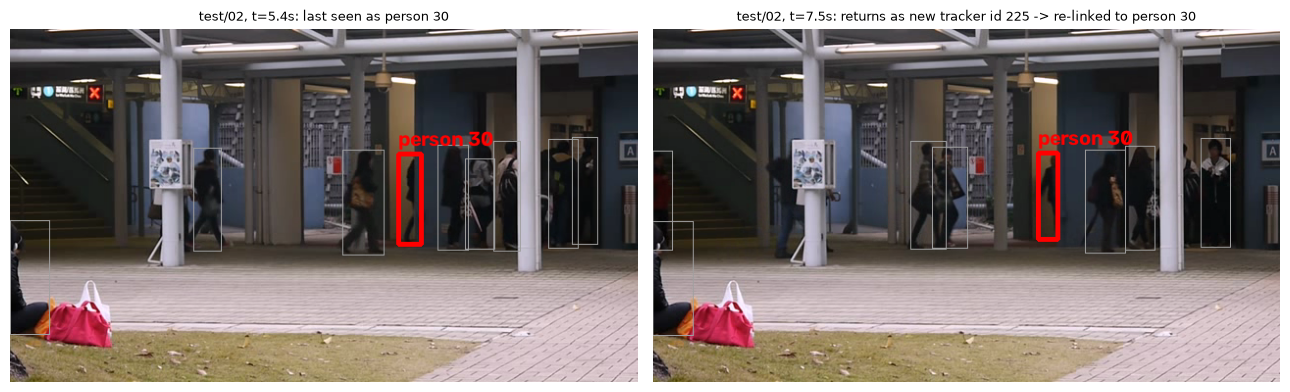

In [9]:
rows = []
for stitch in (False, True):
    c = replace(LOITER_CAM, stitch=stitch)
    summary, _ = headline_table([("x", TEST["avenue"], DEFAULT_RULES, c)], c)
    rows.append({"re-linking": "on" if stitch else "off", **id_fragmentation(TEST["avenue"], c),
                 "event recall %": summary.iloc[0]["Event recall %"]})
display(pd.DataFrame(rows).set_index("re-linking"))
ex = find_relinks(TEST["avenue"], LOITER_CAM, limit=1)
if ex:
    show_grid(relink_panel(ex[0]), cols=2, width=13)

With re-linking, the number of distinct person IDs drops from 1052 to 786 (about 25% fewer broken-up tracks), and event recall doesn't change. Most of the re-links I looked at were correct. In crowds where everyone wears dark clothes the colour check is weak, though, so if that turns out to be a problem the next step is a proper re-identification tracker (BoT-SORT with ReID).

## 6. Bigger YOLO models: is it worth it?
I re-ran everything with the small (`s`) and medium (`m`) versions of YOLO26 and YOLO26-pose, using exactly the same rules,
and compared them with the nano (`n`) version.

In [10]:
pd.read_csv("exp/model_comparison.csv").set_index(["half", "model"]).T

half                       held-out                    tune                
model                       YOLO26m YOLO26n YOLO26s YOLO26m YOLO26n YOLO26s
littering events %             71.0    73.0    72.0    76.5    73.5    77.0
littering right person %       57.0    55.0    56.0    55.2    51.3    55.7
loitering events %             80.0    90.0    80.0    60.0    68.0    68.0
loitering right person %       60.0    70.0    60.0    56.0    48.0    56.0
loitering video skipped %      57.8    45.7    58.9    58.4    51.9    51.6
smoking events %               43.4    28.0    36.8    52.7    42.2    49.9
smoking right person %         14.0     9.9    12.6    20.3    17.7    19.3
littering lift over random     20.6    14.4    15.0    11.2     7.5    10.2
false alarms / min              6.5     6.8     5.9     4.5     5.3     5.1

Speed on my laptop CPU (Apple M3 Pro), one frame at a time, detection + tracking + pose:

In [11]:
lat = pd.read_json("bench_cache/latency.json")
lat.pivot(index="source", columns="model", values="total ms / frame").rename_axis(None, axis=1).add_suffix(" ms/frame")

,YOLO26m ms/frame,YOLO26n ms/frame,YOLO26s ms/frame
source,,,
Littering clip (1920x1080),181.9,55.6,100.9
Loitering video (640x360),191.2,55.7,99.9
Smoking CCTV (640x480),231.8,63.4,125.3


What I take from this:
* **Small (`s`) vs nano (`n`)**: `s` finds more smoking events (37% vs 28% held-out) and gives fewer false alarms (5.9 vs 6.8 per minute), and littering is about the same. Loitering drops from 90% to 80%, but that's 2 events out of 20, and on the tune half the two are tied. In the demo video, the extra event `n` "caught" was actually a false alarm on someone walking past that happened to overlap a labelled event.
* **Medium (`m`)** is the most accurate for smoking (43% of events held-out) and picks the right littering person most reliably (+21 points over random guessing). It's the same as `s` on loitering. But it only runs at 4-5 fps on my laptop CPU, so it can't keep up with live video on our CPU-only setup.
* **Speed**: `s` runs at 8-10 fps on my laptop CPU, which is about real time if we sample video at 10 fps. `n` runs at 16-18 fps.

So I switched Stage 1 to **YOLO26s**, and all the results above use it. If we ever get a GPU, or decide that sampling at 4-5 frames per second is enough, `m` would be the better choice.

## 7. Data problems I had to fix

* **Littering dataset naming.** Every image was called `video_<N>_<frame>`, but each action had its own `video_1..12`, so one filename
  matched up to 30 different frames. I rebuilt the 330 clips by matching each frame to the most similar frame that comes after it
  (script: `scripts/rebuild_littering_clips.py`, output in `data/littering/{train,valid,test}/`). Every match was clear-cut, and I spot-checked 48 clips by eye.
  The original Roboflow split had **only dropping and dumping in valid/test**, so I re-split it with 46/10/10 clips per action.
* **Loitering labels.** The `.mat` files in the folder turned out to be video data, not labels, so I downloaded the official frame labels (`data/loitering/avenue_gt/`).
* **Smoking frames** were shuffled by Roboflow. I put them back in order using the timestamps in the original filenames.
* **Tracker bug on low-fps video.** `model.track()` only returns tracks it has confirmed (seen twice), so at 1 fps about half the smokers never reached my rules.
  I now run the tracker myself and use unconfirmed tracks too, which brought untracked smokers down from ~50% to 5%.

## 8. What's next

1. **Make our own small test set**: 15-30 minutes of continuous footage with staged events (littering, someone loitering for a few minutes, a bag left behind, smoking), with each event's start and end time written down. The public datasets don't match our categories well (3 s littering clips, 1 fps smoking, no real loitering), and this would fix most of that.
2. **Littering by throwing, tossing or dropping**: send the VLM a full-resolution crop around the person so it can spot the item, and try a small litter detector for items COCO doesn't know (wrappers, cans, cigarette butts).
3. **"Walking close past the camera" events** are now missed. If we care about them, a per-camera "restricted zone" rule (draw an area, flag anyone who enters it) is a more general way to cover them than `near_camera` was.
4. **Connect the candidate manifest to the VLM stage** and measure end-to-end with my teammate.
5. **Unattended items**: test on the `unattended_items` data, where bags sit for minutes.

## Appendix: run it on any video or folder of frames

In [12]:
RUN_DEMO = False
SOURCE = "../data/littering/test/dumping_v01_5"     # a video file, a folder of frames, or one image

if RUN_DEMO:
    from stage1_gate import HandoffWriter, Stage1Gate, load_sequence, workload_summary
    seq = load_sequence(SOURCE, fps=10.0)
    writer = HandoffWriter("vlm_handoff_v3")
    result = Stage1Gate(CFG).run(seq, writer=writer)
    print("manifest for the VLM:", writer.write_manifest())
    display(pd.DataFrame([workload_summary(result)]))